In [181]:
import pandas as pd
import matplotlib.pyplot as plt
import sklearn.cluster as cluster
from matplotlib.pyplot import gray, subplot, subplots
from scipy.stats import shapiro
import seaborn as sns
from scipy.stats.mstats import winsorize
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder

from lm import train_c


In [3]:
data = pd.read_csv('spotify.csv')

#Pravimo novi dataset koji sadrži samo pesme čiji speechiness je manji od ili jednak 60
cl_data = data[data["speechiness"] <= 60].copy()

# Bacimo pogleda na podatke koje imamo
cl_data

,track_name,released_year,in_spotify_playlists,in_spotify_charts,streams,in_apple_playlists,in_apple_charts,bpm,mode,energy,instrumentalness,liveness,speechiness
0,Seven (feat. Latto) (Explicit Ver.),2023,553,147,141381703,43,263.0,125,Major,83,0,8,4
1,LALA,2023,1474,48,133716286,48,126.0,92,Major,74,0,10,4
2,vampire,2023,1397,113,140003974,94,207.0,138,Major,53,0,31,6
3,Cruel Summer,2019,7858,-,800840817,116,207.0,170,Major,72,0,11,15
4,WHERE SHE GOES,2023,3133,50,303236322,84,133.0,144,Minor,80,63,11,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...
948,My Mind & Me,2022,953,0,91473363,61,13.0,144,Major,39,0,8,3
949,Bigger Than The Whole Sky,2022,1180,0,121871870,4,0.0,166,Major,24,1,12,6
950,A Veces (feat. Feid),2022,573,0,73513683,2,0.0,92,Major,67,0,8,6
951,En La De Ella,2022,1320,0,133895612,29,26.0,97,Major,77,0,12,5


In [4]:
# Da vidimo kog tipa je svaka promenljiva
cl_data.info()

# Promenljiva in_spotify_charts je tipa object (zapravo se tretira kao String), a trebalo
# bi da bude broj ali to ćemo naknadno videti zašto

<class 'pandas.DataFrame'>
Index: 952 entries, 0 to 952
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   track_name            952 non-null    str    
 1   released_year         952 non-null    int64  
 2   in_spotify_playlists  952 non-null    int64  
 3   in_spotify_charts     951 non-null    str    
 4   streams               952 non-null    int64  
 5   in_apple_playlists    952 non-null    int64  
 6   in_apple_charts       950 non-null    float64
 7   bpm                   952 non-null    int64  
 8   mode                  952 non-null    str    
 9   energy                952 non-null    int64  
 10  instrumentalness      952 non-null    int64  
 11  liveness              952 non-null    int64  
 12  speechiness           952 non-null    int64  
dtypes: float64(1), int64(9), str(3)
memory usage: 104.1 KB


In [5]:
cl_data.drop(columns='track_name', inplace=True)

In [6]:
cl_data['in_spotify_charts'] = pd.to_numeric(cl_data['in_spotify_charts'],errors='coerce')

cl_data.info()

<class 'pandas.DataFrame'>
Index: 952 entries, 0 to 952
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   released_year         952 non-null    int64  
 1   in_spotify_playlists  952 non-null    int64  
 2   in_spotify_charts     950 non-null    float64
 3   streams               952 non-null    int64  
 4   in_apple_playlists    952 non-null    int64  
 5   in_apple_charts       950 non-null    float64
 6   bpm                   952 non-null    int64  
 7   mode                  952 non-null    str    
 8   energy                952 non-null    int64  
 9   instrumentalness      952 non-null    int64  
 10  liveness              952 non-null    int64  
 11  speechiness           952 non-null    int64  
dtypes: float64(2), int64(9), str(1)
memory usage: 96.7 KB


In [9]:
cl_data['mode'].unique()

<StringArray>
['Major', 'Minor']
Length: 2, dtype: str

In [10]:
cl_data['mode'] = cl_data['mode'].map({'Major':0, 'Minor':1})


In [11]:
cl_data.info()

<class 'pandas.DataFrame'>
Index: 952 entries, 0 to 952
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   released_year         952 non-null    int64  
 1   in_spotify_playlists  952 non-null    int64  
 2   in_spotify_charts     950 non-null    float64
 3   streams               952 non-null    int64  
 4   in_apple_playlists    952 non-null    int64  
 5   in_apple_charts       950 non-null    float64
 6   bpm                   952 non-null    int64  
 7   mode                  952 non-null    int64  
 8   energy                952 non-null    int64  
 9   instrumentalness      952 non-null    int64  
 10  liveness              952 non-null    int64  
 11  speechiness           952 non-null    int64  
dtypes: float64(2), int64(10)
memory usage: 96.7 KB


In [13]:
print(cl_data.isna().sum())
print(cl_data.isnull().sum())

released_year           0
in_spotify_playlists    0
in_spotify_charts       2
streams                 0
in_apple_playlists      0
in_apple_charts         2
bpm                     0
mode                    0
energy                  0
instrumentalness        0
liveness                0
speechiness             0
dtype: int64
released_year           0
in_spotify_playlists    0
in_spotify_charts       2
streams                 0
in_apple_playlists      0
in_apple_charts         2
bpm                     0
mode                    0
energy                  0
instrumentalness        0
liveness                0
speechiness             0
dtype: int64


In [19]:
p_s = shapiro(cl_data['in_spotify_charts'].dropna())[1]
print(p_s)
p_a = shapiro(cl_data['in_apple_charts'].dropna())[1]
print(p_a)

cl_data['in_spotify_charts']= cl_data['in_spotify_charts'].fillna(cl_data['in_spotify_charts'].median())
cl_data['in_apple_charts']= cl_data['in_apple_charts'].fillna(cl_data['in_apple_charts'].median())

1.538848995239984e-39
4.919380236580385e-26


In [20]:
print(cl_data.isna().sum())


released_year           0
in_spotify_playlists    0
in_spotify_charts       0
streams                 0
in_apple_playlists      0
in_apple_charts         0
bpm                     0
mode                    0
energy                  0
instrumentalness        0
liveness                0
speechiness             0
dtype: int64


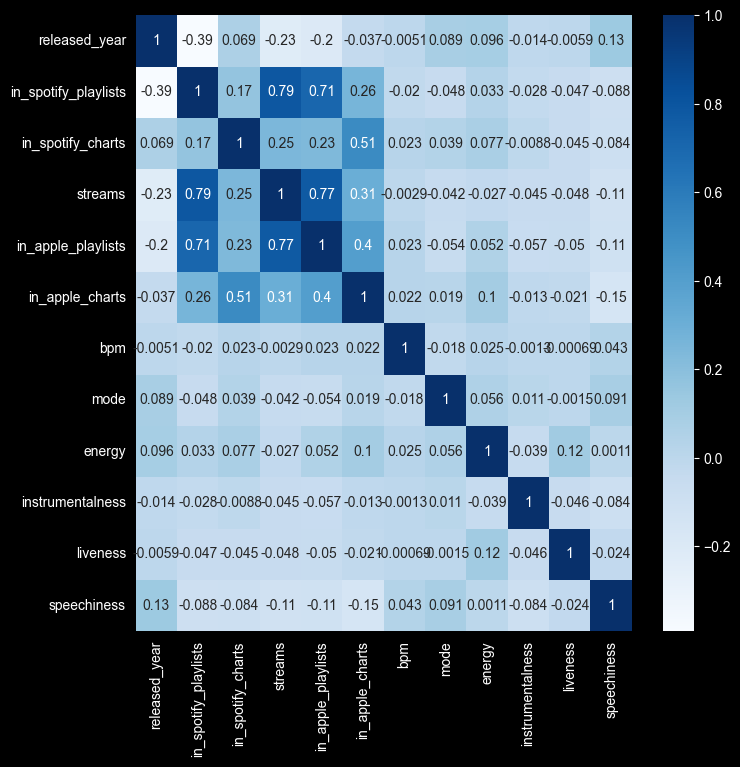

In [26]:
plt.figure(figsize=(8,8))
sns.heatmap(cl_data.corr(), cmap=plt.cm.Blues,annot=True)
plt.show()

In [27]:
cl_data.drop(columns=['in_apple_playlists','streams'], inplace=True)
cl_data.info()

<class 'pandas.DataFrame'>
Index: 952 entries, 0 to 952
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   released_year         952 non-null    int64  
 1   in_spotify_playlists  952 non-null    int64  
 2   in_spotify_charts     952 non-null    float64
 3   in_apple_charts       952 non-null    float64
 4   bpm                   952 non-null    int64  
 5   mode                  952 non-null    int64  
 6   energy                952 non-null    int64  
 7   instrumentalness      952 non-null    int64  
 8   liveness              952 non-null    int64  
 9   speechiness           952 non-null    int64  
dtypes: float64(2), int64(8)
memory usage: 81.8 KB


**Sada se rade UOTLIER-i**

In [47]:
def draw_box(podaci,naziv):
    plt.boxplot(podaci)
    plt.xlabel(naziv)
    plt.show()

In [106]:
draw_box(cl_data['in_spotify_charts'],'in_spotify_charts')
# winsorized_data = winsorize(cl_data['speechiness'],limits=[0.00,0.15])
# draw_box(winsorized_data,'speechiness')
# # cl_data['bpm']=winsorized_data
# cl_data.drop(columns='speechiness', inplace=True)

KeyError: 'in_spotify_charts'

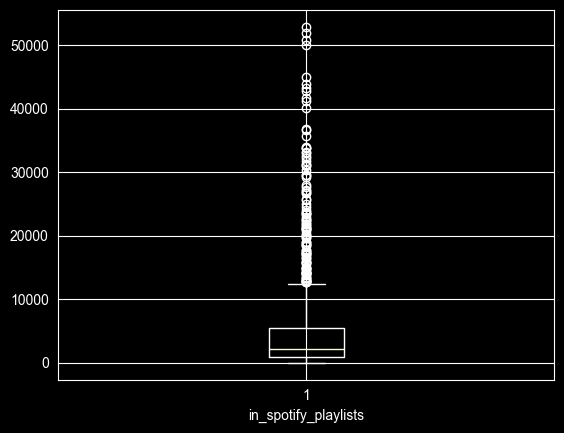

In [48]:
draw_box(cl_data['in_spotify_playlists'],'in_spotify_playlists')

In [49]:
winsorized_data = winsorize( cl_data['in_spotify_playlists'],limits=[0.00,0.10])

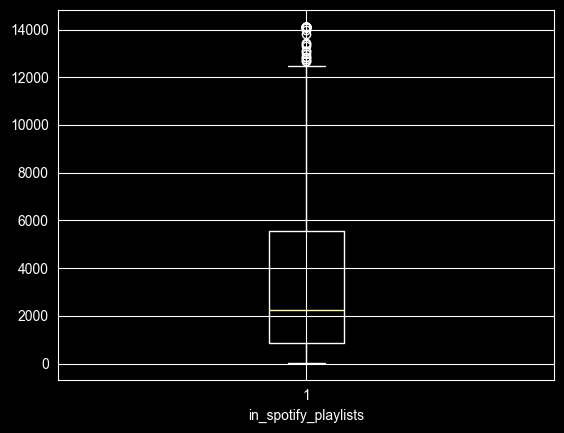

In [50]:
draw_box(winsorized_data,'in_spotify_playlists')

In [51]:
cl_data.drop(columns='in_spotify_playlists', inplace=True)

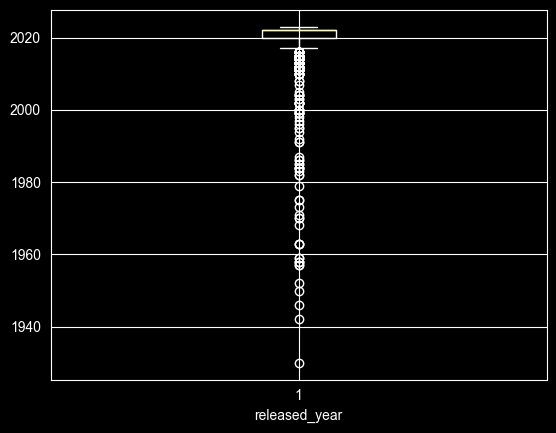

In [52]:
draw_box(cl_data['released_year'],'released_year')

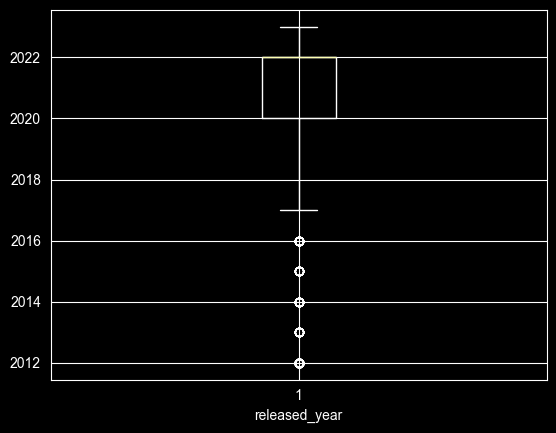

In [55]:
winsorized_data = winsorize(cl_data['released_year'],limits=[0.10,0.00])
draw_box(winsorized_data,'released_year')

In [56]:
cl_data.drop(columns='released_year', inplace=True)

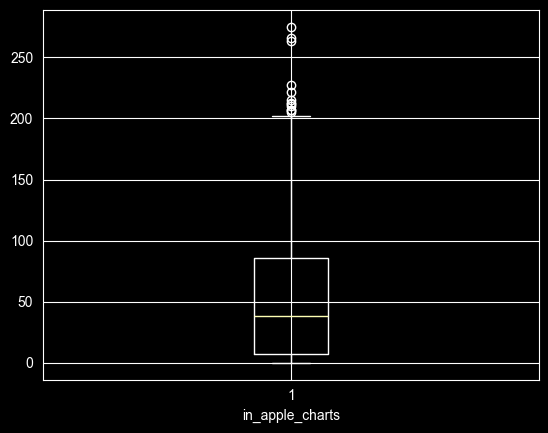

In [64]:
draw_box(cl_data['in_apple_charts'],'in_apple_charts')
winsorized_data = winsorize(cl_data['in_apple_charts'],limits=[0.00,0.02])
cl_data.drop(columns='in_apple_charts', inplace=True)

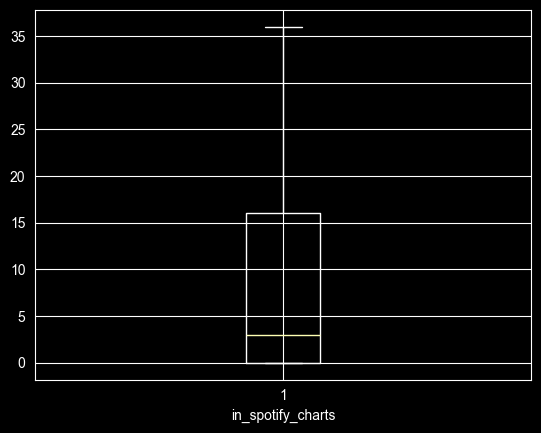

In [68]:
draw_box(cl_data['in_spotify_charts'],'in_spotify_charts')
winsorized_data = winsorize(cl_data['in_spotify_charts'],limits=[0.00,0.10])
draw_box(winsorized_data,'in_spotify_charts')
cl_data.drop(columns='in_spotify_charts', inplace=True)

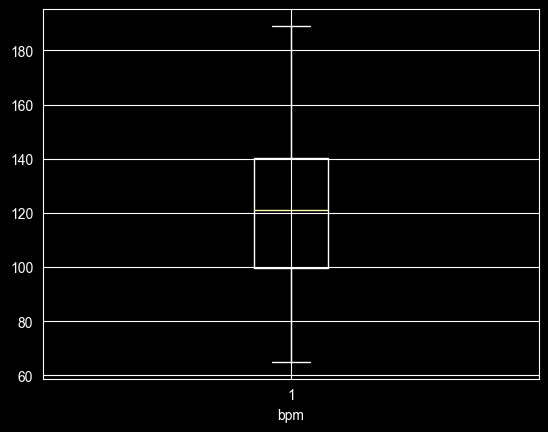

In [75]:
draw_box(cl_data['bpm'],'bpm')
winsorized_data = winsorize(cl_data['bpm'],limits=[0.00,0.01])
draw_box(winsorized_data,'bpm')
cl_data['bpm']=winsorized_data
# cl_data.drop(columns='in_spotify_charts', inplace=True)

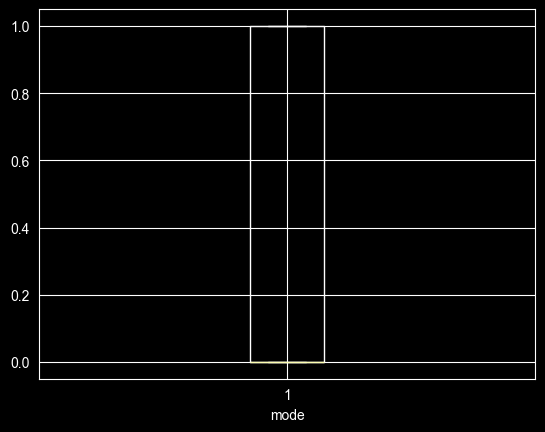

In [76]:
draw_box(cl_data['mode'],'mode')
# winsorized_data = winsorize(cl_data['bpm'],limits=[0.00,0.01])
# draw_box(winsorized_data,'bpm')
# cl_data['bpm']=winsorized_data
# cl_data.drop(columns='in_spotify_charts', inplace=True)

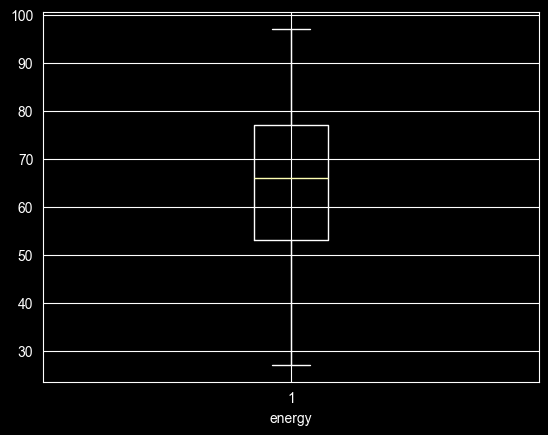

In [82]:
draw_box(cl_data['energy'],'energy')
winsorized_data = winsorize(cl_data['energy'],limits=[0.02,0.00])
draw_box(winsorized_data,'energy')
cl_data['energy']=winsorized_data
# cl_data.drop(columns='in_spotify_charts', inplace=True)

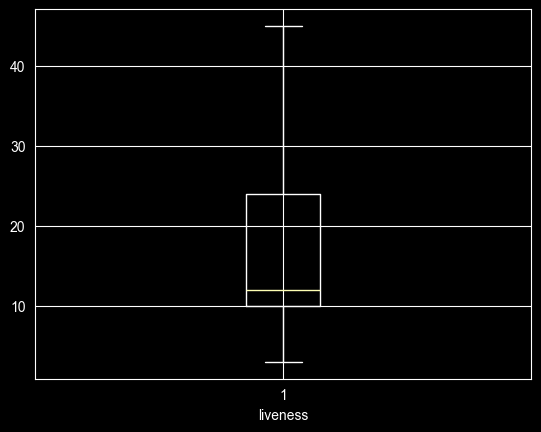

In [91]:
draw_box(cl_data['liveness'],'liveness')
winsorized_data = winsorize(cl_data['liveness'],limits=[0.00,0.05])
draw_box(winsorized_data,'liveness')
cl_data['liveness']=winsorized_data
# cl_data.drop(columns='in_spotify_charts', inplace=True)

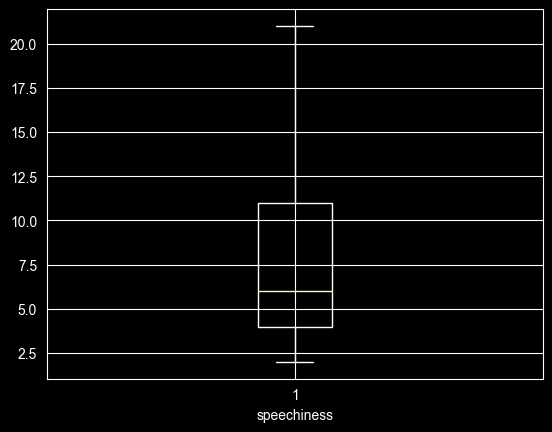

In [100]:
draw_box(cl_data['speechiness'],'speechiness')
winsorized_data = winsorize(cl_data['speechiness'],limits=[0.00,0.15])
draw_box(winsorized_data,'speechiness')
# cl_data['bpm']=winsorized_data
cl_data.drop(columns='speechiness', inplace=True)

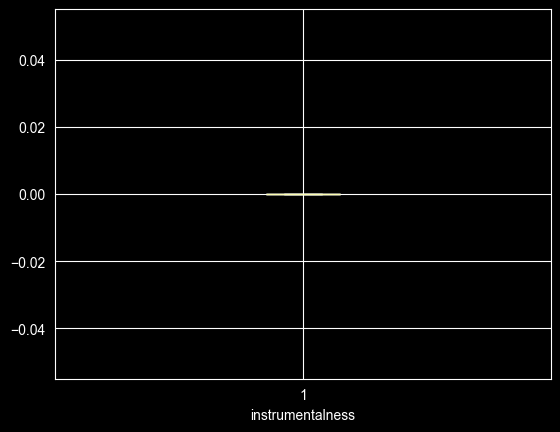

In [104]:
draw_box(cl_data['instrumentalness'],'instrumentalness')
winsorized_data = winsorize(cl_data['instrumentalness'],limits=[0.00,0.10])
draw_box(winsorized_data,'instrumentalness')
# cl_data['bpm']=winsorized_data
cl_data.drop(columns='instrumentalness', inplace=True)

In [105]:
print(cl_data.info())

<class 'pandas.DataFrame'>
Index: 952 entries, 0 to 952
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   bpm       952 non-null    int64
 1   mode      952 non-null    int64
 2   energy    952 non-null    int64
 3   liveness  952 non-null    int64
dtypes: int64(4)
memory usage: 37.2 KB
None


In [111]:
temp_data = MinMaxScaler().fit_transform(cl_data)
cl_data_scaled = pd.DataFrame(temp_data, columns=cl_data.columns)

cl_data_scaled.describe()

,bpm,mode,energy,liveness
count,952.000000,952.000000,952.000000,952.000000
mean,0.463269,0.422269,0.534409,0.344288
std,0.224026,0.494181,0.232333,0.267427
min,0.000000,0.000000,0.000000,0.000000
25%,0.280242,0.000000,0.371429,0.166667
50%,0.451613,0.000000,0.557143,0.214286
75%,0.606855,1.000000,0.714286,0.500000
max,1.000000,1.000000,1.000000,1.000000


In [ ]:
temp_vezba = MinMaxScaler().fit_transform(cl_data)
scaled_vezba = pd.DataFrame(temp_vezba, columns=cl_data.columns)


In [132]:
clustered_data = pd.DataFrame(temp_data, columns=cl_data.columns)

# **ELBOW METODA**

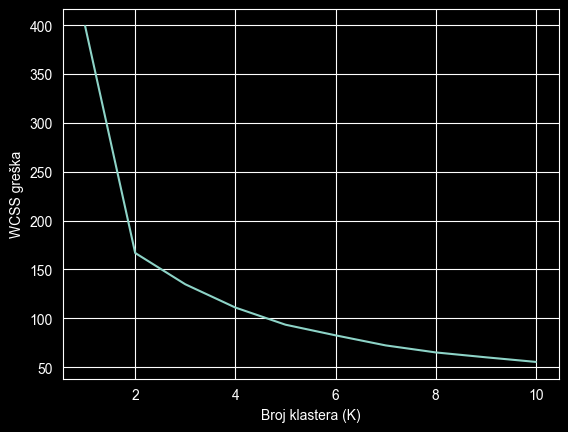

In [125]:
#Primena elbow metode
wcss = []

# Probamo od 1 do 10 klastera
for i in range(1, 11):
    kmeans = cluster.KMeans(n_clusters=i, init='k-means++', max_iter=100, n_init=1000, random_state=0).fit(cl_data_scaled)
    wcss.append(kmeans.inertia_)

plt.plot(range(1, 11), wcss)
plt.xlabel("Broj klastera (K)")
plt.ylabel("WCSS greška")

plt.show()

# wcss
# "Lakat" se pojavljuje kod 2 klastera i kod 4 klastera (drugi "lakat").

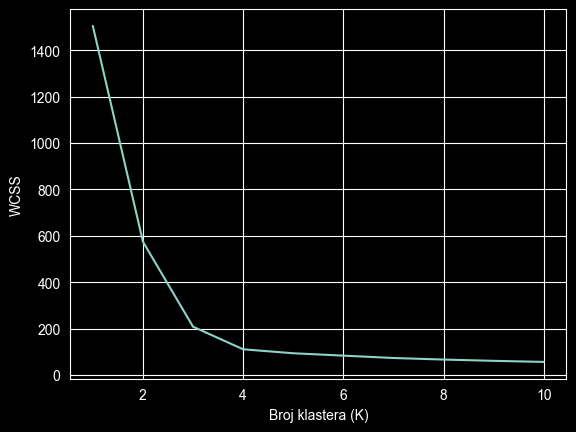

In [177]:
### Vezba za elbow metodu

wc =[]

for i in range(1,11):
    kmeans = cluster.KMeans(n_clusters=i,init='k-means++',n_init=1000,max_iter=100,random_state=0).fit(cl_data_scaled)
    wc.append(kmeans.inertia_)

plt.plot(range(1, 11), wc)
plt.xlabel("Broj klastera (K)")
plt.ylabel("WCSS")
plt.show()

In [124]:
wcss

[399.3227375989541,
 166.900312664734,
 134.8381193190471,
 111.01086581260805,
 93.45839932919006,
 82.55771119915566,
 72.26257747693128,
 65.06963071308026,
 60.07824506203161,
 55.35034145789437]

# **Klasterizacija**

In [142]:
kmeans = cluster.KMeans(n_clusters=2,init='k-means++',max_iter=100,n_init=1000,random_state=0).fit(cl_data_scaled)
kmeans.fit(cl_data_scaled)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",2
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",1000
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",100
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary `.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'


In [143]:
cl_data_scaled["cluster"] = kmeans.labels_

In [144]:
cl_data_scaled

,bpm,mode,energy,liveness,cluster
0,0.483871,0.0,0.800000,0.119048,1
1,0.217742,0.0,0.671429,0.166667,1
2,0.588710,0.0,0.371429,0.666667,1
3,0.846774,0.0,0.642857,0.190476,1
4,0.637097,1.0,0.757143,0.190476,0
...,...,...,...,...,...
947,0.637097,0.0,0.171429,0.119048,1
948,0.814516,0.0,0.000000,0.214286,1
949,0.217742,0.0,0.571429,0.119048,1
950,0.258065,0.0,0.714286,0.214286,1


# **Interpretacija podataka**

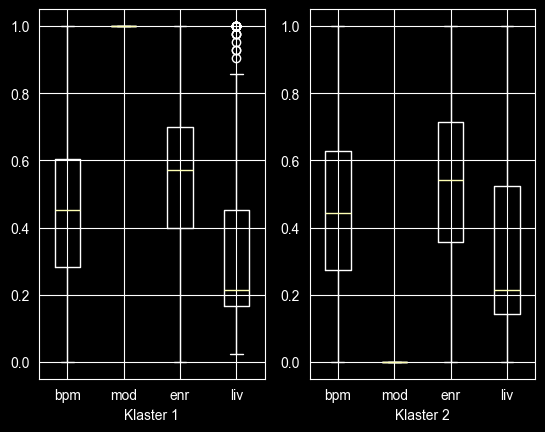

In [154]:
# Iscrtamo i uporedne boxplot-ove za ova dva klastera da bi ih uporedili u smislu sadržaja
fig, ax = plt.subplots(1,2)

# U novijoj verziji matplotlib-a se umesto labels koristi tick_labels
ax[0].boxplot(cl_data_scaled[cl_data_scaled["cluster"]==0].drop(columns = "cluster"), labels=( "bpm", "mod", "enr", "liv"))
ax[0].set_xlabel("Klaster 1")

# U novijoj verziji matplotlib-a se umesto labels koristi tick_labels
ax[1].boxplot(cl_data_scaled[cl_data_scaled["cluster"]==1].drop(columns = "cluster"), labels=("bpm", "mod", "enr", "liv"))
ax[1].set_xlabel("Klaster 2")

plt.show()


In [ ]:
he =  OneHotEncoder(sparse_output=True,drop='first')
p=['a','b']

array = he.fit_transform(cl_data_scaled[p])
col = he.get_feature_names_out(p)

new = pd.DataFrame(array, columns=col,index=cl_data_scaled.index)
cl_data_scaled=cl_data_scaled.drop(columns=p).join(new)


In [150]:

print("Klaster 1, N = ", cl_data_scaled.loc[cl_data_scaled["cluster"]==0, "cluster"].count())
print("Klaster 2, N = ", cl_data_scaled.loc[cl_data_scaled["cluster"]==1, "cluster"].count())

Klaster 1, N =  402
Klaster 2, N =  550


In [ ]:
# Tumačenje

# Veličina klastera
# 1. Prvi klaster ima 402 pesme a drugi 550 pesama, oba su slične veličine.

# 2. Centri klastera
# U klasteru 1 se isključivo nalaze pesme u Minor modu (1) a u klasteru 2 pesme u Major modu (0). Druga, doduše
# minimalna razlika je to da je energy nivo malo niži za pesme iz drugog klastera. Pitanje je da li je ovakva
# klasterizacija naročito smislena jer su po svim ostalim karakteristikama pesme skoro iste u oba klastera.

# 3. Disperzija od centara
# Za oba klastera možemo da kažemo da su skoro iste homogenosti, jedina razlika je u kolonama energy i liveness
# gde je klaster 1 malo homogeniji (manja disperzija). Međutim, disperzija je inače jako velika u oba
# klastera, što opet znači da  bi možda trebalo probati sa klasterizacijom sa četiri klastera.

In [183]:
cl_data_scaled.drop(columns = ["cluster"], inplace=True)

kmeans1 = cluster.KMeans(n_clusters=4,init='k-means++',max_iter=100,n_init=1000,random_state=0)
kmeans1.fit(cl_data_scaled)

cl_data_scaled['cluster']=kmeans1.labels_

In [ ]:
fig,ax =plt.subplots(1,2)
ax[0].boxplot(cl_data_scaled[cl_data_scaled['cluster']==0].drop(columns = "cluster"), labels=( "bpm", "mod", "enr", "liv"))
ax[1].set_xlabel('Klaster§')

ax[0].boxplot(cl_data_scaled[cl_data_scaled['cluster']==1].drop(columns = "cluster"), labels=( "bpm", "mod", "enr", "liv"))
ax[1].set_xlabel('Klaster§')

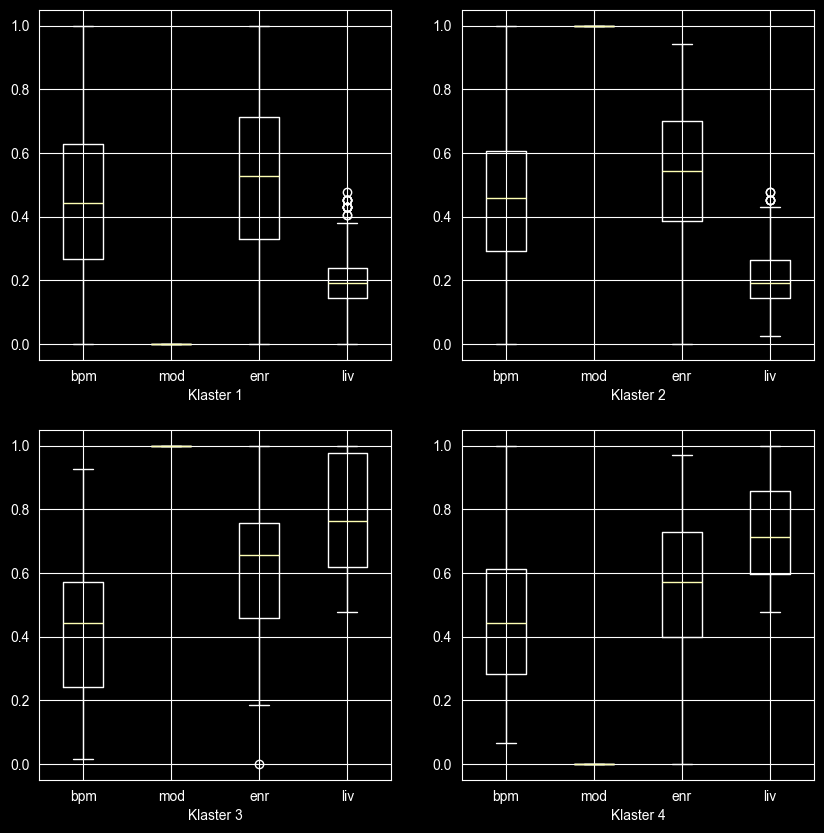

In [189]:
# Iscrtamo i uporedne boxplot-ove za ova četiri klastera da bi ih uporedili u smislu sadržaja
fig, ax = plt.subplots(2,2,figsize=(10,10))

# U novijoj verziji matplotlib-a se umesto labels koristi tick_labels
ax[0,0].boxplot(cl_data_scaled[cl_data_scaled["cluster"]==0].drop(columns = ['cluster']), labels=("bpm", "mod", "enr", "liv"))
ax[0,0].set_xlabel("Klaster 1")

ax[0,1].boxplot(cl_data_scaled[cl_data_scaled["cluster"]==1].drop(columns = ['cluster']), labels=("bpm", "mod", "enr", "liv"))
ax[0,1].set_xlabel("Klaster 2")

ax[1,0].boxplot(cl_data_scaled[cl_data_scaled["cluster"]==2].drop(columns = ['cluster']), labels=("bpm", "mod", "enr", "liv"))
ax[1,0].set_xlabel("Klaster 3")

ax[1,1].boxplot(cl_data_scaled[cl_data_scaled["cluster"]==3].drop(columns = ['cluster']), labels=("bpm", "mod", "enr", "liv"))
ax[1,1].set_xlabel("Klaster 4")

plt.show()



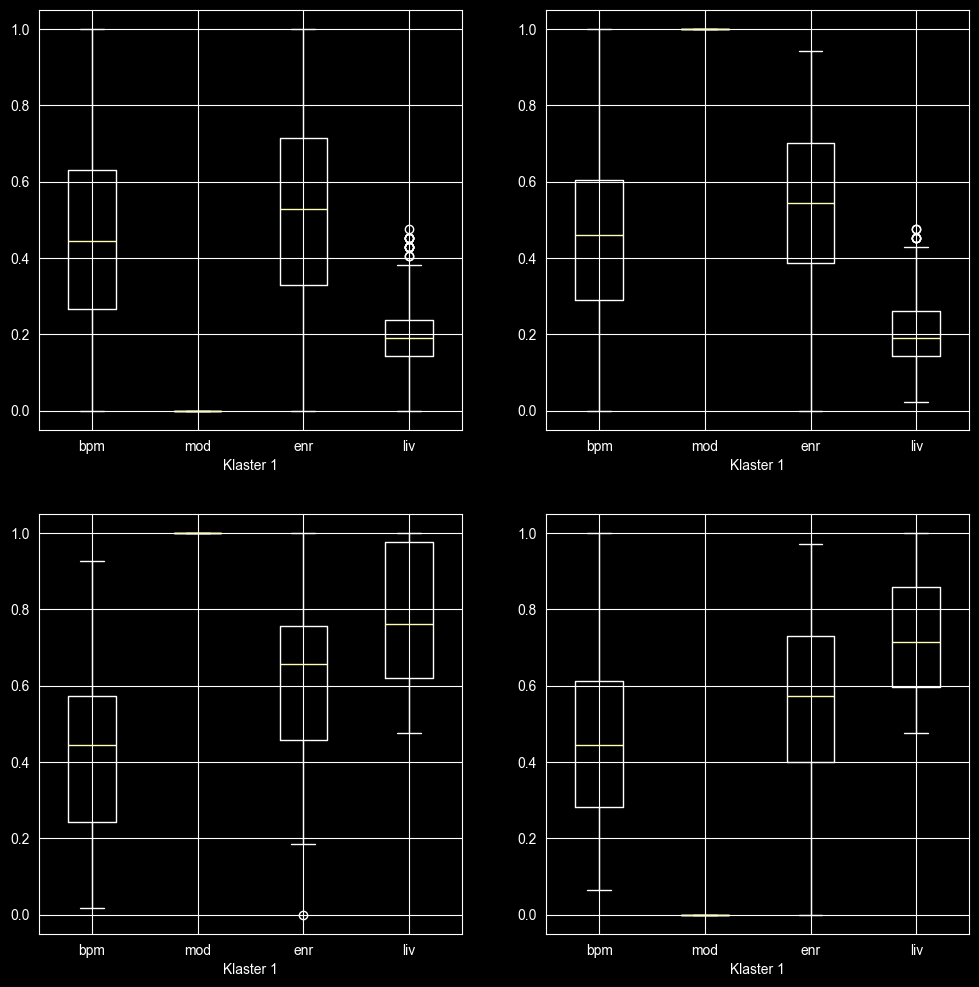

In [199]:
fig, ax = subplots(2,2,figsize=(12,12))

ax[0,0].boxplot(cl_data_scaled[cl_data_scaled["cluster"]==0].drop(columns = ['cluster']), labels=("bpm", "mod", "enr", "liv"))
ax[0,0].set_xlabel("Klaster 1")


ax[0,1].boxplot(cl_data_scaled[cl_data_scaled["cluster"]==1].drop(columns = ['cluster']), labels=("bpm", "mod", "enr", "liv"))
ax[0,1].set_xlabel("Klaster 1")

ax[1,0].boxplot(cl_data_scaled[cl_data_scaled["cluster"]==2].drop(columns = ['cluster']), labels=("bpm", "mod", "enr", "liv"))
ax[1,0].set_xlabel("Klaster 1")

ax[1,1].boxplot(cl_data_scaled[cl_data_scaled["cluster"]==3].drop(columns = ['cluster']), labels=("bpm", "mod", "enr", "liv"))
ax[1,1].set_xlabel("Klaster 1")



plt.show()

In [200]:
print("Klaster 1, N = ", cl_data_scaled.loc[cl_data_scaled["cluster"]==0, "cluster"].count())
print("Klaster 2, N = ", cl_data_scaled.loc[cl_data_scaled["cluster"]==1, "cluster"].count())
print("Klaster 3, N = ", cl_data_scaled.loc[cl_data_scaled["cluster"]==2, "cluster"].count())
print("Klaster 4, N = ", cl_data_scaled.loc[cl_data_scaled["cluster"]==3, "cluster"].count())

Klaster 1, N =  397
Klaster 2, N =  305
Klaster 3, N =  97
Klaster 4, N =  153


In [ ]:
# Tumačenje

# Veličina klastera
# 1. Prvi klaster ima 173 pesme, drugi 245, treći 229 i četvrti 305, svi su značajne veličine.

# 2. Centri klastera
# Klaster 1 sadrži pesme u Minor modu koje su loše rangirane na spotify top listi, dok klaster 2 sadrži
# pesme u Major modu koje su takođe loše rangirane na spotify top listi.
# Nasuprot tome, klasteri 3 i 4 sadrže pesme koje su dobro rangirane na spotify top listi u Minor modu (klaster 3)
# i Major modu (klaster 4) respektivno.
# Razlika između dva klastera sa "dobro rangiranim" pesmama i dva klastera sa "loše rangiranim" pesmama je samo u tome što dobro rangirane pesme (klasteri 3 i 4) imaju malo viši nivo energije (energy).

# 3. Disperzija od centara
# Za klastere 1 i 2 se može reći da su izuzetno homogeni u smislu disperzije od centra klastera po atributu
# in_spotify_charts jer ih isključivo čine loše rangirane pesme, dok su u klasterima 3 i 4 sve ostale pesme sa te top liste, pa je homogenost po tom atributu mnogo manja (odnosno std veća).
# Za klaster 3 važi da je homogeniji od ostalih po atributima energy i liveness.
# Ne postoje bitne razlike u homogenosti između klastera po ostalim atributima.

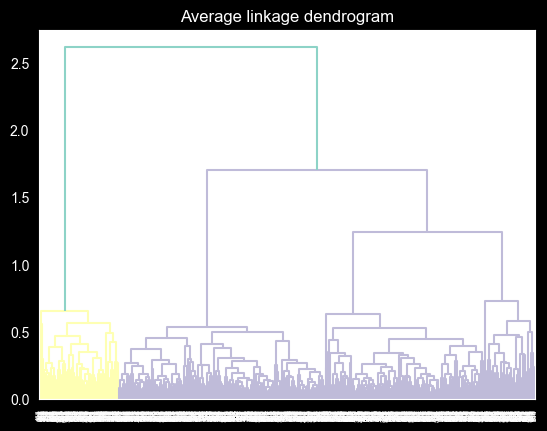

In [201]:
from scipy.cluster.hierarchy import linkage, dendrogram

#Prikaz dendrograma za različite linkage metode
dendrogram(linkage(cl_data_scaled, method='ward', metric='euclidean'))
plt.title("Ward linkage dendrogram")
plt.show()

dendrogram(linkage(cl_data_scaled, method='single', metric='euclidean'))
plt.title("Single linkage dendrogram")
plt.show()

dendrogram(linkage(cl_data_scaled, method='complete', metric='euclidean'))
plt.title("Complete linkage dendrogram")
plt.show()

dendrogram(linkage(cl_data_scaled, method='average', metric='euclidean'))
plt.title("Average linkage dendrogram")
plt.show()

# Ako se izaberu complete ili average linkage metode, dobija se
# po 4 klastera koji su dosta "bliski" jedan drugom (visine na
# dendrogramu nisu prevelike). Sa single i Ward linkage metodama,
# dobijaju se po dva jasno odvojena klastera, sa tim da Ward linkage
# dozvoljava mogućnost podele na 4 klastera (razlika u visini između 2 i 4
# klastera nije velika).
# Zbog svega navedenog, biramo Ward linkage metodu, a probaćemo obe
# varijante - podela na dva klastera i na četiri klastera.